In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully! ✅")

All libraries imported successfully! ✅


In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 1000

df = pd.DataFrame({
    'age': np.random.randint(18, 75, n),
    'job': np.random.choice(['unskilled', 'skilled', 'highly skilled', 'management'], n),
    'credit_amount': np.random.randint(500, 20000, n),
    'duration': np.random.randint(6, 72, n),
    'purpose': np.random.choice(['car', 'furniture', 'education', 'business', 'repairs'], n),
    'savings': np.random.choice(['little', 'moderate', 'quite rich', 'rich'], n),
    'employment': np.random.choice(['unemployed', '<1 year', '1-4 years', '4-7 years', '>7 years'], n),
    'housing': np.random.choice(['own', 'rent', 'free'], n),
    'default': np.random.choice([0, 1], n, p=[0.7, 0.3])
})

df.to_csv("german_credit.csv", index=False)
print(f"Dataset created with {len(df)} records ✅")
print(df.head())

Dataset created with 1000 records ✅
   age             job  credit_amount  duration   purpose     savings  \
0   56       unskilled           5305        53   repairs  quite rich   
1   69         skilled           1306        50       car        rich   
2   46       unskilled           8702        60  business        rich   
3   32         skilled           2368        60   repairs        rich   
4   60  highly skilled          15061        23       car  quite rich   

   employment housing  default  
0    >7 years    rent        0  
1   4-7 years     own        1  
2  unemployed    rent        0  
3   4-7 years     own        0  
4     <1 year    rent        0  


In [3]:
print("Shape:", df.shape)
print("\nColumn types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDefault rate:", df['default'].mean().round(2))

Shape: (1000, 9)

Column types:
 age               int32
job              object
credit_amount     int32
duration          int32
purpose          object
savings          object
employment       object
housing          object
default           int64
dtype: object

Missing values:
 age              0
job              0
credit_amount    0
duration         0
purpose          0
savings          0
employment       0
housing          0
default          0
dtype: int64

Default rate: 0.3


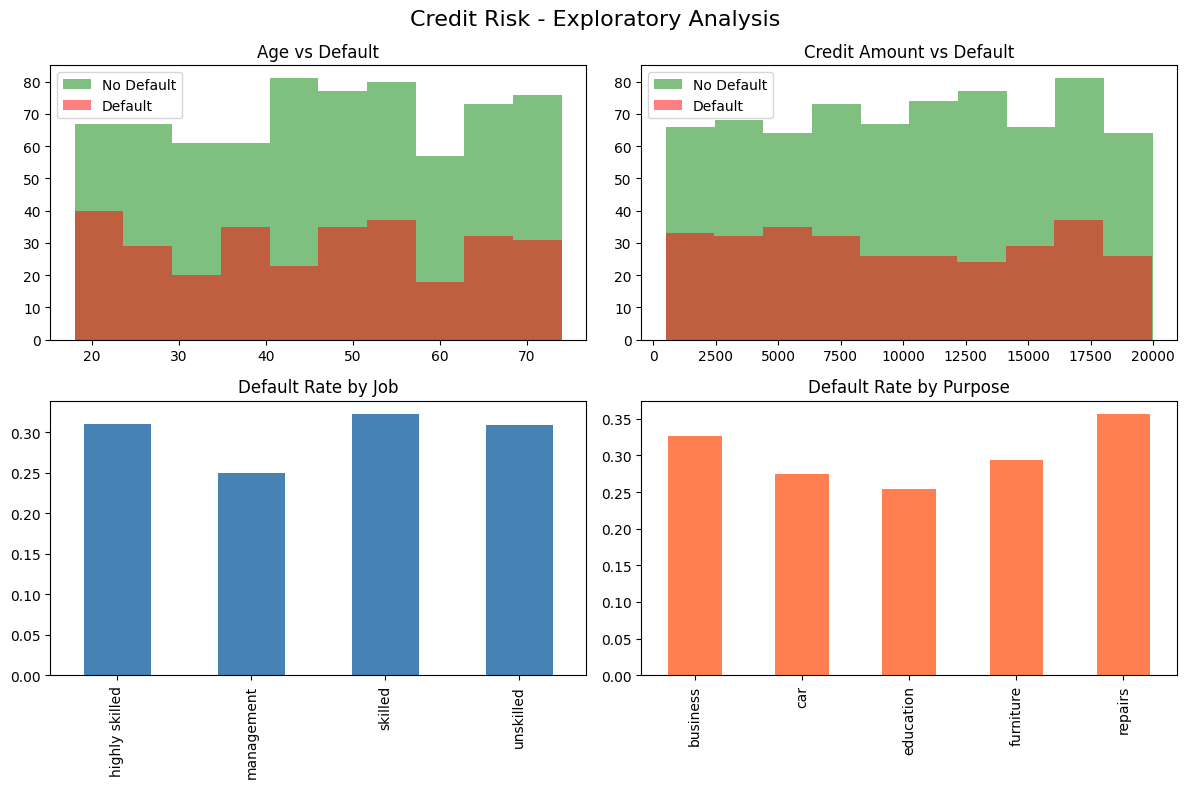

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Credit Risk - Exploratory Analysis', fontsize=16)

# Age distribution
axes[0,0].hist(df[df['default']==0]['age'], alpha=0.5, label='No Default', color='green')
axes[0,0].hist(df[df['default']==1]['age'], alpha=0.5, label='Default', color='red')
axes[0,0].set_title('Age vs Default')
axes[0,0].legend()

# Credit amount
axes[0,1].hist(df[df['default']==0]['credit_amount'], alpha=0.5, label='No Default', color='green')
axes[0,1].hist(df[df['default']==1]['credit_amount'], alpha=0.5, label='Default', color='red')
axes[0,1].set_title('Credit Amount vs Default')
axes[0,1].legend()

# Default by job
df.groupby('job')['default'].mean().plot(kind='bar', ax=axes[1,0], color='steelblue')
axes[1,0].set_title('Default Rate by Job')
axes[1,0].set_xlabel('')

# Default by purpose
df.groupby('purpose')['default'].mean().plot(kind='bar', ax=axes[1,1], color='coral')
axes[1,1].set_title('Default Rate by Purpose')
axes[1,1].set_xlabel('')

plt.tight_layout()
plt.show()

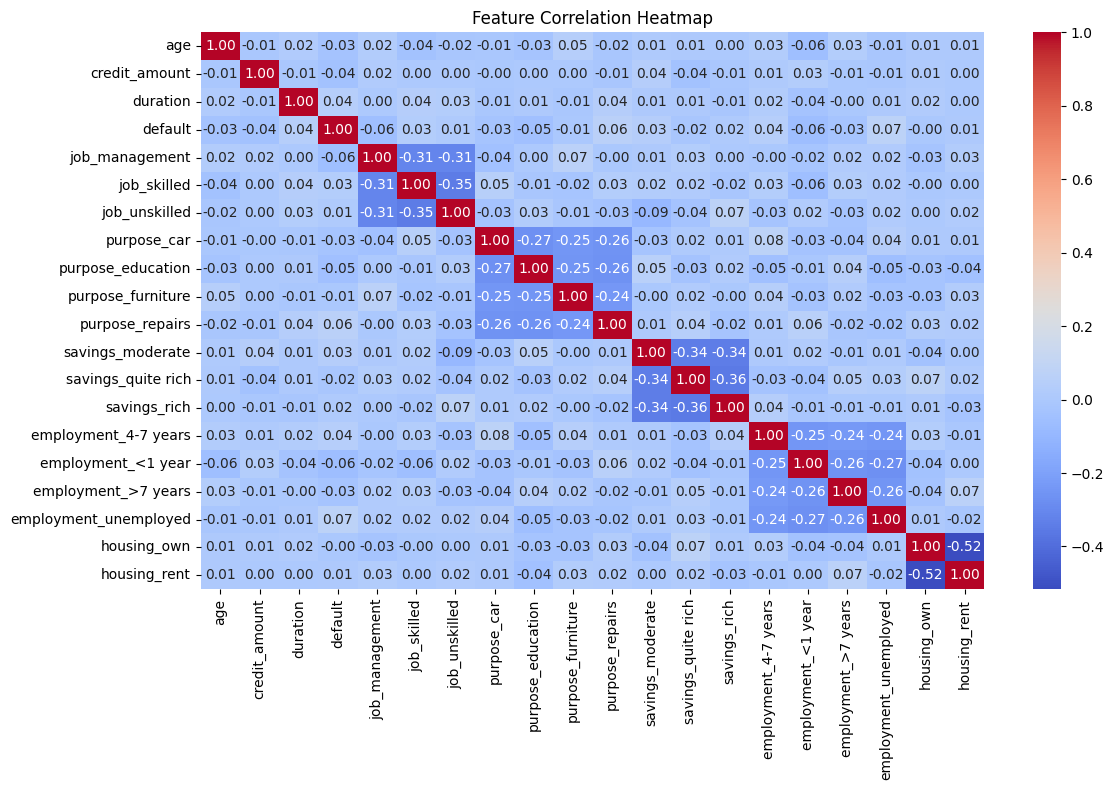

In [5]:
# Encode categorical columns for correlation
df_encoded = pd.get_dummies(df, drop_first=True)

plt.figure(figsize=(12, 8))
sns.heatmap(df_encoded.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Encode categorical columns
df_model = df.copy()
le = LabelEncoder()
cat_cols = ['job', 'purpose', 'savings', 'employment', 'housing']
for col in cat_cols:
    df_model[col] = le.fit_transform(df_model[col])

# Split features and target
X = df_model.drop('default', axis=1)
y = df_model['default']

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {len(X_train)} ✅")
print(f"Testing samples: {len(X_test)} ✅")

Training samples: 800 ✅
Testing samples: 200 ✅


In [7]:
import mlflow
import mlflow.sklearn

# Start MLflow experiment
mlflow.set_experiment("credit-risk-model")

with mlflow.start_run():
    # Train Random Forest model
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    
    # Make predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:,1]
    
    # Calculate metrics
    auc = roc_auc_score(y_test, y_prob)
    
    # Log metrics to MLflow
    mlflow.log_param("n_estimators", 100)
    mlflow.log_metric("auc_roc", auc)
    
    # Log model
    mlflow.sklearn.log_model(model, "credit-risk-model")
    
    print(f"AUC-ROC Score: {auc:.4f} ✅")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

2026/04/01 16:15:24 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/04/01 16:15:24 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instea

AUC-ROC Score: 0.5256 ✅

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.99      0.83       142
           1       0.33      0.02      0.03        58

    accuracy                           0.70       200
   macro avg       0.52      0.50      0.43       200
weighted avg       0.60      0.70      0.60       200



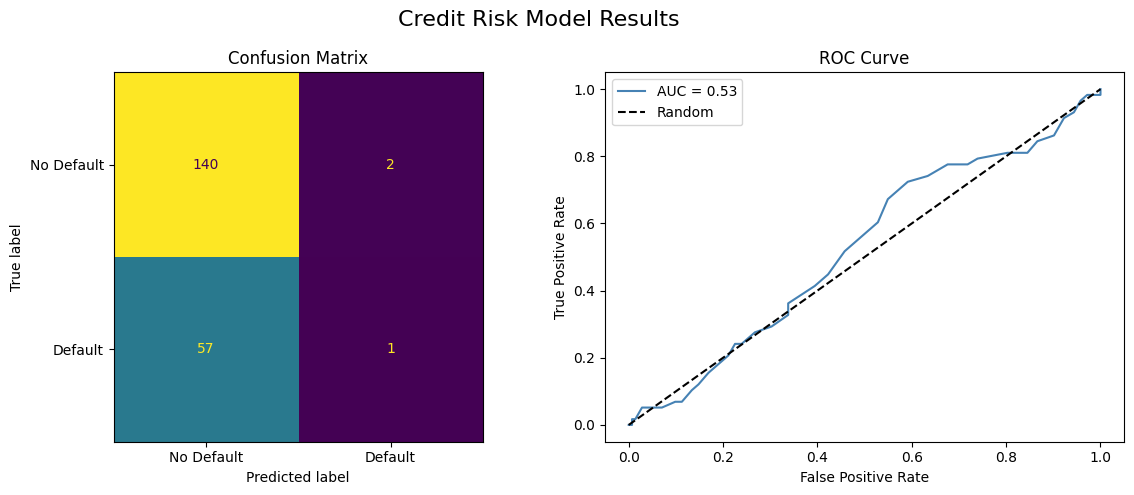

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Credit Risk Model Results', fontsize=16)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Default', 'Default'])
disp.plot(ax=axes[0], colorbar=False)
axes[0].set_title('Confusion Matrix')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='steelblue', label=f'AUC = {auc:.2f}')
axes[1].plot([0,1], [0,1], 'k--', label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.show()

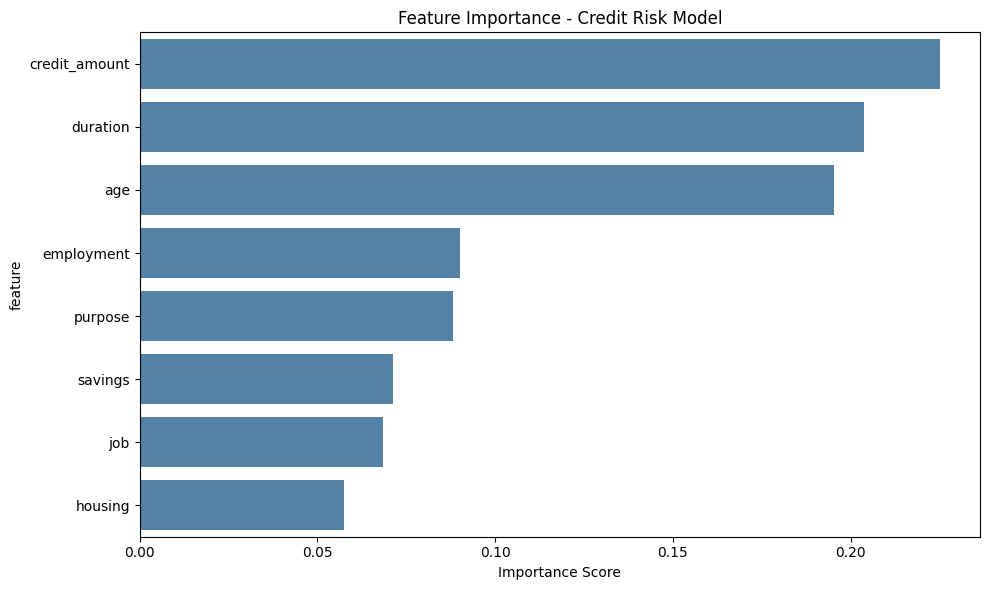


Top features:
         feature  importance
2  credit_amount    0.225156
3       duration    0.203888
0            age    0.195432
6     employment    0.090025
4        purpose    0.088242
5        savings    0.071199
1            job    0.068488
7        housing    0.057571


In [9]:
# Feature Importance
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='importance', y='feature', color='steelblue')
plt.title('Feature Importance - Credit Risk Model')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print("\nTop features:")
print(feature_importance)

In [10]:
import mlflow.sklearn
from mlflow.tracking import MlflowClient

# Register the model
client = MlflowClient()

# Get the latest run
runs = mlflow.search_runs(experiment_names=["credit-risk-model"])
best_run_id = runs.iloc[0].run_id

# Register model
model_uri = f"runs:/{best_run_id}/credit-risk-model"
registered_model = mlflow.register_model(model_uri, "CreditRiskModel")

print(f"Model registered successfully! ✅")
print(f"Model name: {registered_model.name}")
print(f"Model version: {registered_model.version}")

Registered model 'CreditRiskModel' already exists. Creating a new version of this model...
2026/04/01 16:15:54 WARNING mlflow.tracking._model_registry.fluent: Run with id 4a4a5070b49240f6b316a4dab59a269f has no artifacts at artifact path 'credit-risk-model', registering model based on models:/m-67a3aeda1e2c406aafdc2428781f9d66 instead
Created version '4' of model 'CreditRiskModel'.


Model registered successfully! ✅
Model name: CreditRiskModel
Model version: 4


In [11]:
import fairlearn
import shap
print(f"Fairlearn version: {fairlearn.__version__} ✅")
print(f"SHAP version: {shap.__version__} ✅")

Fairlearn version: 0.13.0 ✅
SHAP version: 0.51.0 ✅


In [12]:
from fairlearn.metrics import MetricFrame, selection_rate, false_positive_rate
from sklearn.metrics import accuracy_score

# Create age groups
df_test = X_test.copy()
df_test['actual'] = y_test.values
df_test['predicted'] = y_pred

age_groups = pd.cut(X_test['age'], bins=[18, 30, 45, 60, 75], 
                    labels=['18-30', '31-45', '46-60', '61-75'])

# Create MetricFrame
metric_frame = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate
    },
    y_true=y_test,
    y_pred=y_pred,
    sensitive_features=age_groups
)

print("Fairness metrics by age group:")
print(metric_frame.by_group)
print(f"\nAccuracy disparity: {metric_frame.difference()['accuracy']:.4f}")
print(f"Selection rate disparity: {metric_frame.difference()['selection_rate']:.4f}")

TypeError: '<' not supported between instances of 'str' and 'float'

In [ ]:
from fairlearn.metrics import MetricFrame, selection_rate
from sklearn.metrics import accuracy_score

# Reset index to align everything
X_test_reset = X_test.reset_index(drop=True)
y_test_reset = y_test.reset_index(drop=True)
y_pred_series = pd.Series(y_pred).reset_index(drop=True)

# Force age to standard int
age_values = X_test_reset['age'].astype(int).tolist()
age_series = pd.Series(age_values)

# Create age groups
age_groups = pd.cut(
    age_series,
    bins=[17, 30, 45, 60, 76],
    labels=['18-30', '31-45', '46-60', '61-75']
)

print("Age groups created successfully:")
print(age_groups.value_counts())

In [ ]:
# Create MetricFrame
metric_frame = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate
    },
    y_true=y_test_reset,
    y_pred=y_pred_series,
    sensitive_features=age_groups
)

print("Fairness metrics by age group:")
print(metric_frame.by_group)
print(f"\nAccuracy disparity: {metric_frame.difference()['accuracy']:.4f}")
print(f"Selection rate disparity: {metric_frame.difference()['selection_rate']:.4f}")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Fairness Analysis by Age Group', fontsize=16)

# Accuracy by group
metric_frame.by_group['accuracy'].plot(
    kind='bar', ax=axes[0], color='steelblue', rot=0)
axes[0].set_title('Accuracy by Age Group')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0, 1)

# Selection rate by group
metric_frame.by_group['selection_rate'].plot(
    kind='bar', ax=axes[1], color='coral', rot=0)
axes[1].set_title('Selection Rate by Age Group')
axes[1].set_ylabel('Selection Rate')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [ ]:
import shap

# Create SHAP explainer
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_reset)

# Summary plot
plt.figure()
shap.summary_plot(shap_values[:,:,1], X_test_reset, show=True)

In [ ]:
# SHAP bar plot - average feature importance
plt.figure()
shap.summary_plot(shap_values[:,:,1], X_test_reset, plot_type="bar", show=True)

In [ ]:
print("=" * 50)
print("   CREDIT RISK MODEL - RESPONSIBLE AI REPORT")
print("=" * 50)

print("\n📊 MODEL PERFORMANCE")
print(f"   AUC-ROC Score:        {auc:.4f}")
print(f"   Overall Accuracy:     {accuracy_score(y_test_reset, y_pred_series):.4f}")

print("\n⚖️  FAIRNESS ANALYSIS (Age Groups)")
print(f"   Accuracy Disparity:   {metric_frame.difference()['accuracy']:.4f}")
print(f"   Selection Disparity:  {metric_frame.difference()['selection_rate']:.4f}")
print("\n   Accuracy by group:")
for group, row in metric_frame.by_group.iterrows():
    print(f"   {group}: {row['accuracy']:.2f}")

print("\n🔍 TOP 3 MOST IMPORTANT FEATURES (SHAP)")
top_features = feature_importance.head(3)
for _, row in top_features.iterrows():
    print(f"   {row['feature']}: {row['importance']:.4f}")

print("\n✅ MODEL REGISTERED")
print(f"   Name:     CreditRiskModel")
print(f"   Version:  2")
print("=" * 50)